<center>
  <h1><b>FuzzyPooling</b></h1>
  <h3>Validação da Classe</h3>
  <b>Júlia Guedes A. dos Santos & Yasmin B. Shimizu</b>
</center>


<p style="text-align: center;">
  Parte do Trabalho de Conclusão de Curso <b>Redes neurais clássicas e fuzzy para segmentação de imagens de microscopia eletrônica: desempenho e impactos socioambientais</b>, desenvolvido na Ilum Escola de Ciência do Centro Nacional de Pesquisa em Energia e Materiais (CNPEM) para obtenção do título de Bacharel em Ciência e Tecnologia.
</p>

<center>
  <img src="https://github.com/yasminbshimizu/FP-UNet_TEM/blob/main/imagens_README/logos_ilumcnpem.png?raw=true" width="1000"/>
</center>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from skimage import io, color, transform
from skimage import img_as_ubyte
from sklearn.model_selection import train_test_split
from fuzzy_pooling import FuzzyPooling, ConjsFuzzy


### **Conjuntos Fuzzy**

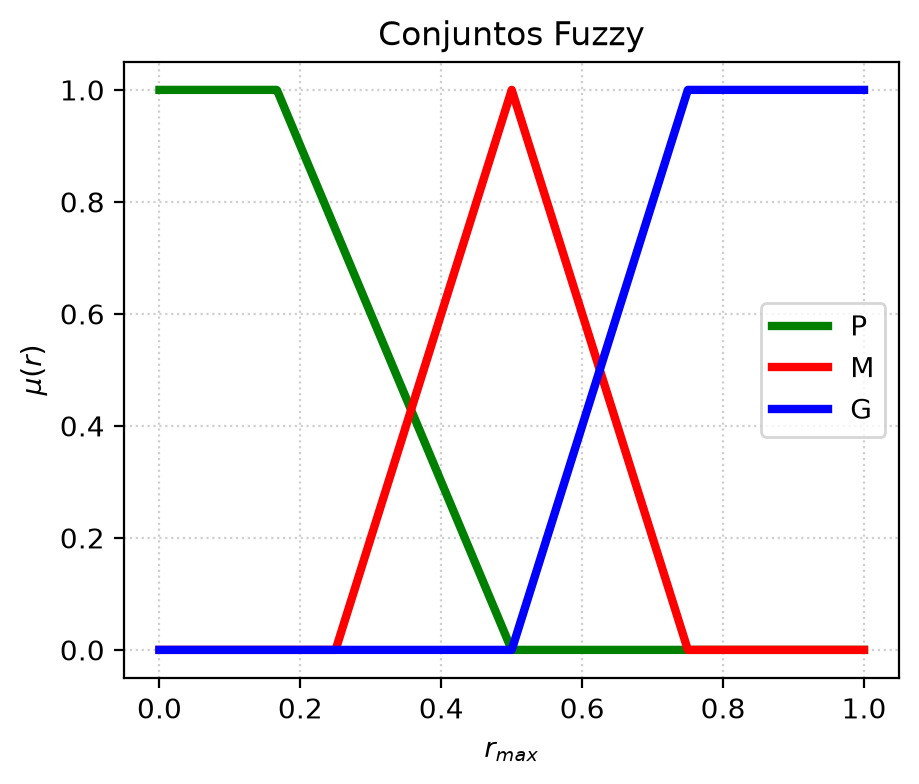

In [2]:
rmax = 1

x = torch.Tensor(np.linspace(0, rmax, 1001))
x_dim = x.unsqueeze(0).unsqueeze(0).unsqueeze(0)  # (1, 1, 1, 1001)

fpert = ConjsFuzzy(rmax)
conjs = fpert(x_dim)

conjs = conjs.squeeze().detach()  # (3, 1001)

plt.figure(figsize=(5,4), dpi=200)
plt.plot(x, conjs[0], lw = 3, label= "P", color= "green")
plt.plot(x, conjs[1], lw = 3, label = "M", color= "red")
plt.plot(x, conjs[2], lw = 3, label= "G", color="blue")
plt.xlabel(r"$r_{max}$")
plt.ylabel(r"$\mu(r)$")
plt.title("Conjuntos Fuzzy")
plt.grid(alpha=0.6, linestyle=":")
plt.legend()
plt.show()

## **Teste 1**: Matriz Pequena

Para o primeiro teste da classe construída, foi calculada a saída esperada para o FuzzyPooling manualmente, e o resultado da cada etapa foi comparado ao resultado obtido pela implementação computacional.

Assim a partir de um patch 
$ p =\begin{bmatrix}
\frac{3}{2} & 2 & \frac{5}{2} \\
\frac{3}{2} & \frac{5}{2} & \frac{7}{2} \\
\frac{9}{2} & 4 & \frac{9}{2} 
\end{bmatrix}  $
foram calculadas as matrizes de pertinência aos conjuntos pequeno, médio e grande

$ \pi_P = \begin{bmatrix}
\frac{3}{4} & \frac{1}{2} & \frac{1}{4} \\
\frac{3}{4} & \frac{1}{4} & 0 \\
0 & 0 & 0 
\end{bmatrix}  $;
$ \quad \pi_M = \begin{bmatrix}
0 & \frac{1}{3} & \frac{2}{3} \\
0 & \frac{2}{3} & \frac{2}{3} \\
0 & \frac{1}{3} & 0 
\end{bmatrix}  $;
$ \quad \pi_G = \begin{bmatrix}
0 & 0 & 0 \\
0 & 0 & \frac{1}{3} \\
1 & \frac{2}{3} & 1 
\end{bmatrix}  $, 

cujos scores, calculados por somatório algébrico, foram de $s_{\pi_P} = \frac{503}{512} = 0.98242$, $s_{\pi_M} = \frac{239}{243} = 0.98354$, e $s_{\pi_G} = 1$.

Desse modo, o patch $\pi_G$ foi selecionado, e o centro de gravidade calculado foi de $\frac{77}{18} = 4,2\bar{7}$.

Ou seja, o valor final obtido com a redução de dimensionalidade do patch $p$ através de FuzzyPooling foi de $4,2\bar{7}$, enquanto o MaxPolling resultaria em $max(p) = 4.5$.

Aplicando o MaxPooling, obtivemos o valor esperado de $4,5$.

In [3]:
p1 = torch.tensor([[1.5, 2, 2.5],[1.5, 2.5, 3.5],[4.5, 4, 4.5]])
p1 = p1.unsqueeze(0).unsqueeze(0)

MaxPool = nn.MaxPool2d(kernel_size=3, stride=2)
teste1_max = MaxPool(p1)
print("MaxPooling: ", teste1_max[0,0,0,0])

MaxPooling:  tensor(4.5000)


Aplicando para o FuzzyPooling, o valor esperado, de $4,2\bar{7}$, também foi alcançado.

In [4]:
p1 = torch.tensor([[1.5, 2, 2.5],[1.5, 2.5, 3.5],[4.5, 4, 4.5]])

p1 = p1.unsqueeze(0).unsqueeze(0) # Adequação ao formato de entrada da classe

FP1 = FuzzyPooling(tamanho_kernel=3, stride=2,padding=0)
teste1 = FP1(p1)

print("FuzzyPooling: ", teste1) #[0,0,0,0])

FuzzyPooling:  tensor([[[[4.2778]]]])


Abrindo as etapas do FuzzyPooling, é possível verificar também que todos os resultados intermediários correspondem ao esperado.

In [5]:
print("\n", "#"*45, "\n", "#"*10, "FUZZY POOLING - Teste 1", "#"*10 , "\n", "#"*45, "\n")

print("###### Patches ######")
print(FP1.patches) #[0,0])
print("\n \n")

print("###### Patches Fuzzy ######")
print("Pequeno ~ Score: ", FP1.scores) #[0,0,0,0])
print(FP1.matrizes_pi) #[0,0,0])
print("\n")
print("Médio ~ Score: ", FP1.scores) #[0,0,1,0])
print(FP1.matrizes_pi) #[0,0,1])
print("\n")
print("Grande ~ Score: ", FP1.scores) #[0,0,2,0])
print(FP1.matrizes_pi) #[0,0,2])
print("\n \n")

print("###### Patch Fuzzy Selecionado ######")
print(FP1.patches_fuzzy) #[0,0])
print("\n \n")

print("###### Centro de Gravidade ######")
print(FP1.valores_fuzzy) #[0,0,0,0])


 ############################################# 
 ########## FUZZY POOLING - Teste 1 ########## 
 ############################################# 

###### Patches ######
tensor([[[[1.5000],
          [2.0000],
          [2.5000],
          [1.5000],
          [2.5000],
          [3.5000],
          [4.5000],
          [4.0000],
          [4.5000]]]])

 

###### Patches Fuzzy ######
Pequeno ~ Score:  tensor([[[[0.9824],
          [0.9835],
          [1.0000]]]])
tensor([[[[[0.7500],
           [0.5000],
           [0.2500],
           [0.7500],
           [0.2500],
           [0.0000],
           [0.0000],
           [0.0000],
           [0.0000]],

          [[0.0000],
           [0.3333],
           [0.6667],
           [0.0000],
           [0.6667],
           [0.6667],
           [0.0000],
           [0.3333],
           [0.0000]],

          [[0.0000],
           [0.0000],
           [0.0000],
           [0.0000],
           [0.0000],
           [0.3333],
           [1.0000],
       

Desse modo, o método foi implementado com sucesso, retornando resultados correspondentes a sua execução manual.

## **Teste 2**: Dados do Artigo

In [6]:
# Define as transformações básicas (redimensionar e converter para Tensor)
usc_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((256, 256)),
    transforms.ToTensor()
])

# Use the same SAME-padded 3x3/stride-2 grid for every pooling method.
# Explicit zero padding also makes average pooling use the same samples as
# fuzzy pooling. Nearest-neighbor restoration avoids adding a smoothing
# operation that is not part of pooling. The paper does not document its
# restoration method, so this choice is reported rather than hidden.
def crisp_pool_same(x, method, kernel_size=3, stride=2):
    h, w = x.shape[-2:]
    h_out = (h + stride - 1) // stride
    w_out = (w + stride - 1) // stride
    pad_h = max((h_out - 1) * stride + kernel_size - h, 0)
    pad_w = max((w_out - 1) * stride + kernel_size - w, 0)
    padding = (pad_w // 2, pad_w - pad_w // 2, pad_h // 2, pad_h - pad_h // 2)
    x = F.pad(x, padding)
    if method == "max":
        return F.max_pool2d(x, kernel_size, stride)
    if method == "average":
        return F.avg_pool2d(x, kernel_size, stride)
    raise ValueError(f"Unknown pooling method: {method}")

def restore_size(x, size=(256, 256)):
    return F.interpolate(x, size=size, mode="nearest")

# Carrega o dataset direto da pasta. O artigo usa 44 imagens; o diretório
# local contém 39, portanto estes resultados não são uma reprodução exata.
usc_dataset = datasets.ImageFolder(root='../misc', transform=usc_transform)
usc_dataloader = DataLoader(usc_dataset, batch_size=len(usc_dataset), shuffle=False)
usc_images, _ = next(iter(usc_dataloader))
usc_images = usc_images * 255
print(f"Imagens USC locais: {len(usc_dataset)} (artigo: 44)")

Imagens USC locais: 40 (artigo: 44)


In [7]:
method = ["Imagem Original", "MaxPooling", "AvgPooling", "FuzzyPooling"]
n_images = usc_images.shape[0]

teste2 = torch.zeros(
      (4, n_images, 1, 256, 256),
      dtype=usc_images.dtype,
      device=usc_images.device,
  )

teste2[0,:,:,:,:] = usc_images

im_max = crisp_pool_same(usc_images, "max")
im_max_rsz = restore_size(im_max)

teste2[1,:,:,:,:] = im_max_rsz

im_avg = crisp_pool_same(usc_images, "average")
im_avg_rsz = restore_size(im_avg)
teste2[2,:,:,:,:] = im_avg_rsz

FP2 = FuzzyPooling(tamanho_kernel=3, stride=2, funcs_pertinencia=ConjsFuzzy(rmax=255))
im_fzz = FP2(usc_images)
im_fzz_rsz = restore_size(im_fzz)
teste2[3,:,:,:,:] = im_fzz_rsz

In [8]:
crms = np.zeros((4,n_images)) #método, imagem

for i in range(n_images):
    for p in range(4):
        crms[p,i] = torch.std(teste2[p,i,:,:,:], correction=0)

for p in range(4):
    print(method[p], " ~ Crms Médio: ", np.mean(crms[p,:]))

Imagem Original  ~ Crms Médio:  41.63695611953735
MaxPooling  ~ Crms Médio:  37.718010801076886
AvgPooling  ~ Crms Médio:  39.45071420669556
FuzzyPooling  ~ Crms Médio:  43.68897819519043


In [9]:
from skimage.metrics import peak_signal_noise_ratio

psnr = np.zeros((3,n_images)) #método, imagem

for i in range(n_images):
    for p in range(3):
        psnr[p,i] = peak_signal_noise_ratio(
            teste2[0,i,:,:,:].squeeze().numpy(),
            teste2[p+1,i,:,:,:].squeeze().numpy(),
            data_range=255
        )

for p in range(3):
    print(method[p+1], " ~ PSNR Médio: ", np.mean(psnr[p,:]))

MaxPooling  ~ PSNR Médio:  22.046210264905753
AvgPooling  ~ PSNR Médio:  26.20397087843572
FuzzyPooling  ~ PSNR Médio:  21.76323824875806


In [10]:
from skimage.metrics import structural_similarity

ssim = np.zeros((3,n_images)) #método, imagem  

for i in range(n_images):
    for p in range(3):
        ssim[p,i] = structural_similarity(
            teste2[0,i,:,:,:].squeeze().numpy(),
            teste2[p+1,i,:,:,:].squeeze().numpy(),
            data_range=255
        )

for p in range(3): 
    print(method[p+1], " ~ SSIM Médio: ", np.mean(ssim[p,:]))

print("\nReferência do artigo (44 imagens; reconstrução não especificada):")
print("MaxPooling   ~ RMS 44.28 | PSNR 5.29 dB | SSIM 0.72")
print("AvgPooling   ~ RMS 47.98 | PSNR 5.29 dB | SSIM 0.78")
print("FuzzyPooling ~ RMS 48.19 | PSNR 5.42 dB | SSIM 0.77")

MaxPooling  ~ SSIM Médio:  0.7338512877681362
AvgPooling  ~ SSIM Médio:  0.8242824890725611
FuzzyPooling  ~ SSIM Médio:  0.8042006092960866

Referência do artigo (44 imagens; reconstrução não especificada):
MaxPooling   ~ RMS 44.28 | PSNR 5.29 dB | SSIM 0.72
AvgPooling   ~ RMS 47.98 | PSNR 5.29 dB | SSIM 0.78
FuzzyPooling ~ RMS 48.19 | PSNR 5.42 dB | SSIM 0.77


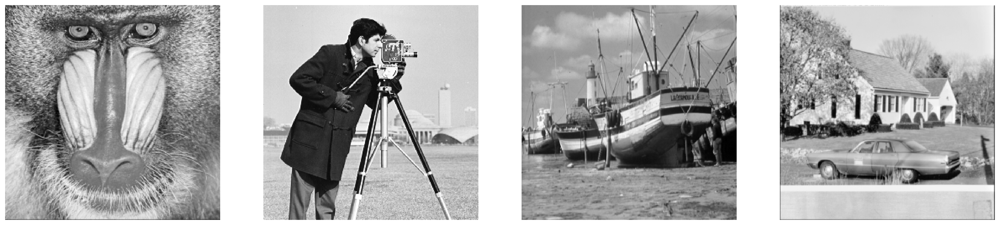

In [11]:
im_size = (256,256)

im_baboon_rgb = io.imread("../USC_Images_Validation/baboon.tiff")
im_baboon_gray = color.rgb2gray(im_baboon_rgb)
im_baboon_norm = transform.resize(im_baboon_gray, im_size)
im_baboon_arr = img_as_ubyte(im_baboon_norm)
im_baboon = torch.Tensor(im_baboon_arr).unsqueeze(0).unsqueeze(0)

im_cam_gray = io.imread("../USC_Images_Validation/cameraman.png")
im_cam_norm =  transform.resize(im_cam_gray, im_size)
im_cam_arr = img_as_ubyte(im_cam_norm)
im_cam = torch.Tensor(im_cam_arr).unsqueeze(0).unsqueeze(0)

im_fboat_gray = io.imread("../USC_Images_Validation/fishing_boat.tiff")
im_fboat_norm =  transform.resize(im_fboat_gray, im_size)
im_fboat_arr = img_as_ubyte(im_fboat_norm)
im_fboat = torch.Tensor(im_fboat_arr).unsqueeze(0).unsqueeze(0)

im_house_rgb = io.imread("../USC_Images_Validation/house.tiff")
im_house_gray = color.rgb2gray(im_house_rgb)
im_house_norm =  transform.resize(im_house_gray, im_size)
im_house_arr = img_as_ubyte(im_house_norm)
im_house = torch.Tensor(im_house_arr).unsqueeze(0).unsqueeze(0)

fig, axes = plt.subplots(1, 4, figsize=(25, 6), dpi=200)
axes[0].imshow(im_baboon[0,0,:,:], cmap='gray')
axes[1].imshow(im_cam[0,0,:,:], cmap='gray')
axes[2].imshow(im_fboat[0,0,:,:], cmap='gray')
axes[3].imshow(im_house[0,0,:,:], cmap='gray')
axes[0].axis("off"); axes[1].axis("off"); axes[2].axis("off"); axes[3].axis("off")
plt.show()

torch.Size([4, 1, 256, 256])


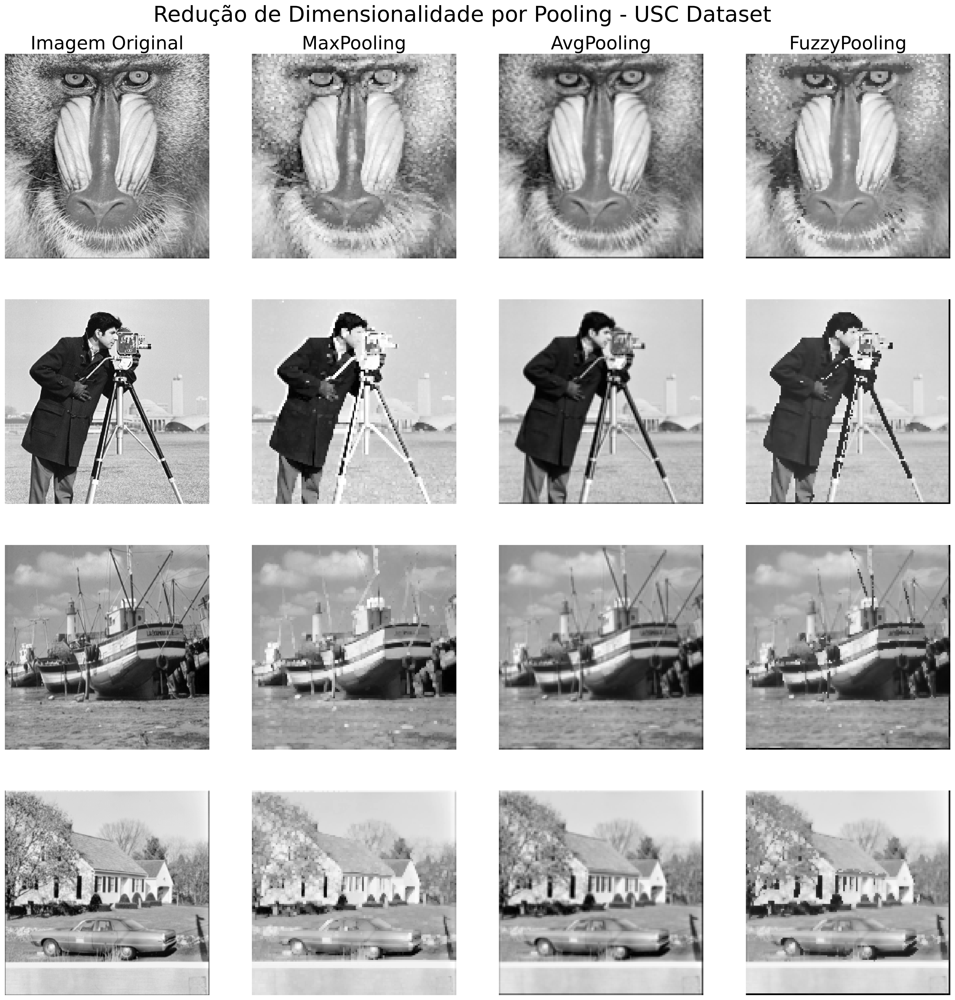

In [12]:
teste2 = torch.zeros((4,4,1,256,256)) #método, batch, canal, altura, largura

teste2[0,0,:,:,:] = im_baboon
teste2[0,1,:,:,:] = im_cam
teste2[0,2,:,:,:] = im_fboat
teste2[0,3,:,:,:] = im_house

print(teste2[0,:,:,:,:].shape)

titles = ["Baboon", "Cameraman", "Fishing Boat", "House"]
method = ["Imagem Original", "MaxPooling", "AvgPooling", "FuzzyPooling"]

im_max = crisp_pool_same(teste2[0,:,:,:,:], "max")
im_max_rsz = restore_size(im_max)
teste2[1,:,:,:,:] = im_max_rsz

im_avg = crisp_pool_same(teste2[0,:,:,:,:], "average")
im_avg_rsz = restore_size(im_avg)
teste2[2,:,:,:,:] = im_avg_rsz

FP2 = FuzzyPooling(tamanho_kernel=3, stride=2, funcs_pertinencia=ConjsFuzzy(rmax=255))
im_fzz = FP2(teste2[0,:,:,:,:])
im_fzz_rsz = restore_size(im_fzz)
teste2[3,:,:,:,:] = im_fzz_rsz


fig, axes = plt.subplots(4, 4, figsize=(25, 25), dpi=200)

for i in range(4):
    axes[0,i].set_title(method[i], fontsize=27)
    for p in range(4):
            axes[i,p].imshow(teste2[p,i,0,:,:], cmap='gray')
            axes[i,p].axis("off")

fig.suptitle("Redução de Dimensionalidade por Pooling - USC Dataset", fontsize=32, y=0.92)
plt.show()

In [13]:
crms = np.zeros((4,4)) #método, imagem

for i in range(4):
    for p in range(4):
        crms[p,i] = torch.std(teste2[p,i,0,:,:], correction=0)

for p in range(4):
    print(method[p], " ~ Crms Médio: ", np.mean(crms[p,:]))

Imagem Original  ~ Crms Médio:  49.56147289276123
MaxPooling  ~ Crms Médio:  44.1209774017334
AvgPooling  ~ Crms Médio:  46.8703088760376
FuzzyPooling  ~ Crms Médio:  51.1499547958374


In [14]:
from skimage.metrics import peak_signal_noise_ratio

psnr = np.zeros((3,4)) #método, imagem

for i in range(4):
    for p in range(3):
        psnr[p,i] = peak_signal_noise_ratio(
            teste2[0,i,0,:,:].squeeze().numpy(),
            teste2[p+1,i,0,:,:].squeeze().numpy(),
            data_range=255
        )

for p in range(3):
    print(method[p+1], " ~ PSNR Médio: ", np.mean(psnr[p,:]))

MaxPooling  ~ PSNR Médio:  18.688174945825704
AvgPooling  ~ PSNR Médio:  23.54807810291286
FuzzyPooling  ~ PSNR Médio:  20.163207462305056


In [15]:
from skimage.metrics import structural_similarity

ssim = np.zeros((3,4)) #método, imagem  

for i in range(4):
    for p in range(3):
        ssim[p,i] = structural_similarity(
            teste2[0,i,0,:,:].squeeze().numpy(),
            teste2[p+1,i,0,:,:].squeeze().numpy(),
            data_range=255
        )

for p in range(3): 
    print(method[p+1], " ~ SSIM Médio: ", np.mean(ssim[p,:]))

MaxPooling  ~ SSIM Médio:  0.6468725399312805
AvgPooling  ~ SSIM Médio:  0.7499960929680681
FuzzyPooling  ~ SSIM Médio:  0.7242325747092322


## **Teste 3**: Dados do Projeto

Por fim, foram realizados testes para os dados utilizados no projeto, a fim de realizar uma análise prévia de como o FuzzyPooling se comporta neste contexto. Para isso, utilizamos tanto as imagens de grafeno quanto as de $\text{MoS}_2$.

In [16]:
graphene_dataset = np.load('../graphene_dataset0.npz')
graphene_images = graphene_dataset['images']

_, graphene_images = train_test_split(
       graphene_images, test_size=0.2, random_state=42)

graphene_img = graphene_images[0]

In [17]:
mos2_dataset = np.load('../mos2_dataset_0.npz')
mos2_images = mos2_dataset['images']

_, mos2_images = train_test_split(
       mos2_images, test_size=0.2, random_state=42)

mos2_img = mos2_images[0]

### **3.1** Redução de Dimensionalidade das Imagens

In [18]:
testeg3_max = crisp_pool_same(torch.as_tensor(graphene_img), "max")
testeg3_max = restore_size(testeg3_max.unsqueeze(0), size=(512,512))

testem3_max = crisp_pool_same(torch.as_tensor(mos2_img), "max")
testem3_max = restore_size(testem3_max.unsqueeze(0), size=(512,512))

In [19]:
testeg3_avg = crisp_pool_same(torch.as_tensor(graphene_img), "average")
testeg3_avg = restore_size(testeg3_avg.unsqueeze(0), (512,512))

testem3_avg = crisp_pool_same(torch.as_tensor(mos2_img), "average")
testem3_avg = restore_size(testem3_avg.unsqueeze(0), (512,512))

In [20]:
FP3 = FuzzyPooling(tamanho_kernel=3, stride=2, funcs_pertinencia=ConjsFuzzy(rmax=1))

testeg3_fuzzy = FP3([graphene_img])
testeg3_fuzzy = restore_size(testeg3_fuzzy, (512,512))

testem3_fuzzy = FP3([mos2_img])
testem3_fuzzy = restore_size(testem3_fuzzy, (512, 512))

c:\Users\yasmin24023\OneDrive - ILUM ESCOLA DE CIÊNCIA\26.2 - 6° Período\26.2 - TCC\26.2 - Projeto Final\08.2. Fuzzy Pooling\fuzzy_pooling_revised\fuzzy_pooling.py:417: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_new.cpp:255.)
  x = torch.as_tensor(x)


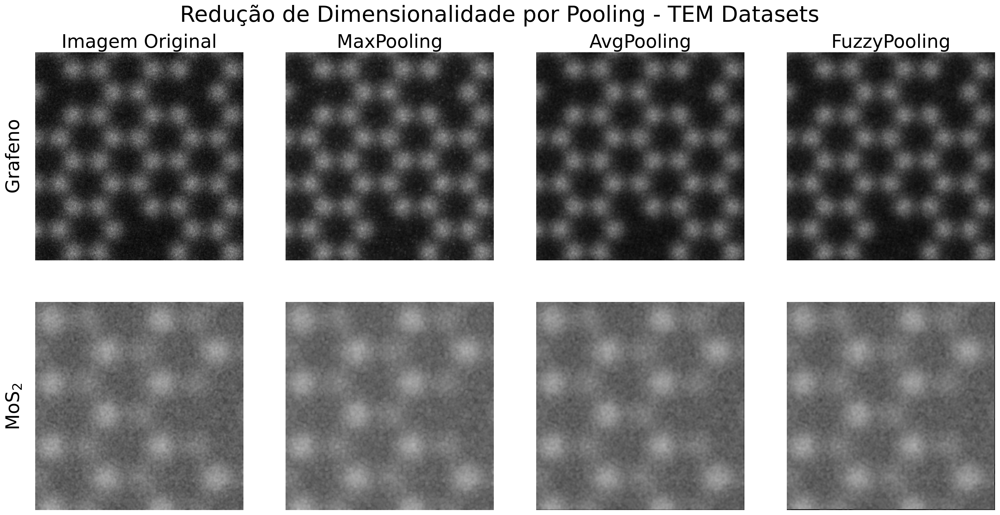

In [21]:
fig, axes = plt.subplots(2, 4, figsize=(25, 12), dpi=200)

fig.suptitle("Redução de Dimensionalidade por Pooling - TEM Datasets", fontsize=32, y=0.96)

axes[0, 0].text(
    -0.1, 0.5, "Grafeno",
    transform=axes[0, 0].transAxes,
    rotation=90,
    va="center",
    ha="center",
    fontsize=27
)


axes[1, 0].text(
    -0.1, 0.5, r"MoS$_2$",
    transform=axes[1, 0].transAxes,
    rotation=90,
    va="center",
    ha="center",
    fontsize=27
)

axes[0,0].set_title("Imagem Original", fontsize=27)
axes[0,0].imshow(graphene_img[0], cmap='gray', vmin=0, vmax=1)

axes[0,1].set_title("MaxPooling", fontsize=27)
axes[0,1].imshow(testeg3_max[0,0], cmap='gray', vmin=0, vmax=1)

axes[0,2].set_title("AvgPooling", fontsize=27)
axes[0,2].imshow(testeg3_avg[0,0], cmap='gray', vmin=0, vmax=1)

axes[0,3].set_title("FuzzyPooling", fontsize=27)
axes[0,3].imshow(testeg3_fuzzy[0,0], cmap='gray', vmin=0, vmax=1)

axes[1,0].imshow(mos2_img[0], cmap='gray', vmin=0, vmax=1)
axes[1,1].imshow(testem3_max[0,0], cmap='gray', vmin=0, vmax=1)
axes[1,2].imshow(testem3_avg[0,0], cmap='gray', vmin=0, vmax=1)
axes[1,3].imshow(testem3_fuzzy[0,0], cmap='gray', vmin=0, vmax=1)

axes[0,0].axis("off"); axes[0,1].axis("off"); axes[0,2].axis("off"); axes[0,3].axis("off");axes[1,0].axis("off"); axes[1,1].axis("off"); axes[1,2].axis("off"); axes[1,3].axis("off")
plt.show()


In [22]:
teste3g = [[torch.tensor(img_as_ubyte(graphene_img))], torch.tensor(img_as_ubyte(testeg3_max)), torch.tensor(img_as_ubyte(testeg3_avg)), torch.tensor(img_as_ubyte(testeg3_fuzzy))]
teste3m = [[torch.tensor(img_as_ubyte(mos2_img))], torch.tensor(img_as_ubyte(testem3_max)), torch.tensor(img_as_ubyte(testem3_avg)), torch.tensor(img_as_ubyte(testem3_fuzzy))]

In [23]:
crms_g = np.zeros((4)) 
crms_m = np.zeros((4)) 

for p in range(4):
    g = torch.as_tensor(teste3g[p][0][0]).float()
    m = torch.as_tensor(teste3m[p][0][0]).float()

    crms_g[p] = torch.std(g, correction=0)
    crms_m[p] = torch.std(m, correction=0)


print("##### Grafeno #####")
for p in range(4):
    print(method[p], " ~ Crms: ", crms_g[p])
print()
print("##### MoS2 #####")
for p in range(4):
    print(method[p], " ~ Crms: ", crms_m[p])

##### Grafeno #####
Imagem Original  ~ Crms:  27.605302810668945
MaxPooling  ~ Crms:  28.824094772338867
AvgPooling  ~ Crms:  27.20208168029785
FuzzyPooling  ~ Crms:  27.315534591674805

##### MoS2 #####
Imagem Original  ~ Crms:  17.30111312866211
MaxPooling  ~ Crms:  17.100383758544922
AvgPooling  ~ Crms:  17.363195419311523
FuzzyPooling  ~ Crms:  18.399986267089844


In [24]:
psnr_g = np.zeros((3)) #método, imagem
psnr_m = np.zeros((3)) #método, imagem


for p in range(3):

    img_g_ref = teste3g[0][0].numpy()
    img_g = teste3g[p+1][0].numpy()

    img_m_ref = teste3m[0][0].numpy()
    img_m = teste3m[p+1][0].numpy()

    psnr_g[p] = peak_signal_noise_ratio(
        img_g_ref,
        img_g,
        data_range=255
    )

    psnr_m[p] = peak_signal_noise_ratio(
        img_m_ref,
        img_m,
        data_range=255
    )


print("##### Grafeno #####")
for p in range(3):
    print(method[p+1], " ~ PSNR: ", psnr_g[p])
    
print()
print("##### MoS2 #####")
for p in range(3):
    print(method[p+1], " ~ PSNR: ", psnr_m[p])

##### Grafeno #####
MaxPooling  ~ PSNR:  28.924994485246053
AvgPooling  ~ PSNR:  34.736887772577916
FuzzyPooling  ~ PSNR:  34.41240034893587

##### MoS2 #####
MaxPooling  ~ PSNR:  34.142456613198384
AvgPooling  ~ PSNR:  35.94642501864571
FuzzyPooling  ~ PSNR:  30.13611633155091


In [25]:
ssim_g = np.zeros((3)) #método, imagem
ssim_m = np.zeros((3)) #método, imagem


for p in range(3):

    img_g_ref = teste3g[0][0][0].numpy()
    img_g = teste3g[p+1][0][0].numpy()

    img_m_ref = teste3m[0][0][0].numpy()
    img_m = teste3m[p+1][0][0].numpy()

    ssim_g[p] = structural_similarity(
        img_g_ref,
        img_g,
        data_range=255
    )

    ssim_m[p] = structural_similarity(
        img_m_ref,
        img_m,
        data_range=255
    )
    

print("##### Grafeno #####")
for p in range(3): 
    print(method[p+1], " ~ SSIM Médio: ", ssim_g[p])

print()
print("##### MoS2 #####")
for p in range(3): 
    print(method[p+1], " ~ SSIM Médio: ", ssim_m[p])

##### Grafeno #####
MaxPooling  ~ SSIM Médio:  0.8278275270495682
AvgPooling  ~ SSIM Médio:  0.8841237057992584
FuzzyPooling  ~ SSIM Médio:  0.8828193820394031

##### MoS2 #####
MaxPooling  ~ SSIM Médio:  0.9244642261194572
AvgPooling  ~ SSIM Médio:  0.945355613556081
FuzzyPooling  ~ SSIM Médio:  0.943635583101921


### **3.2** Adequação à um bloco da U-Net

In [26]:
import torch.nn as nn

class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU6(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU6(inplace=True),
        )

    def forward(self, x):
        return self.conv(x)
 

#### Grafeno

In [27]:
imagem = graphene_img.astype(np.float32)
input_data = torch.from_numpy(imagem).unsqueeze(0)

In [28]:
torch.manual_seed(42)
conv = DoubleConv(1, 16)
convolucao = conv(input_data)

Text(0.5, 0.92, 'Canais Convolucionais - Grafeno')

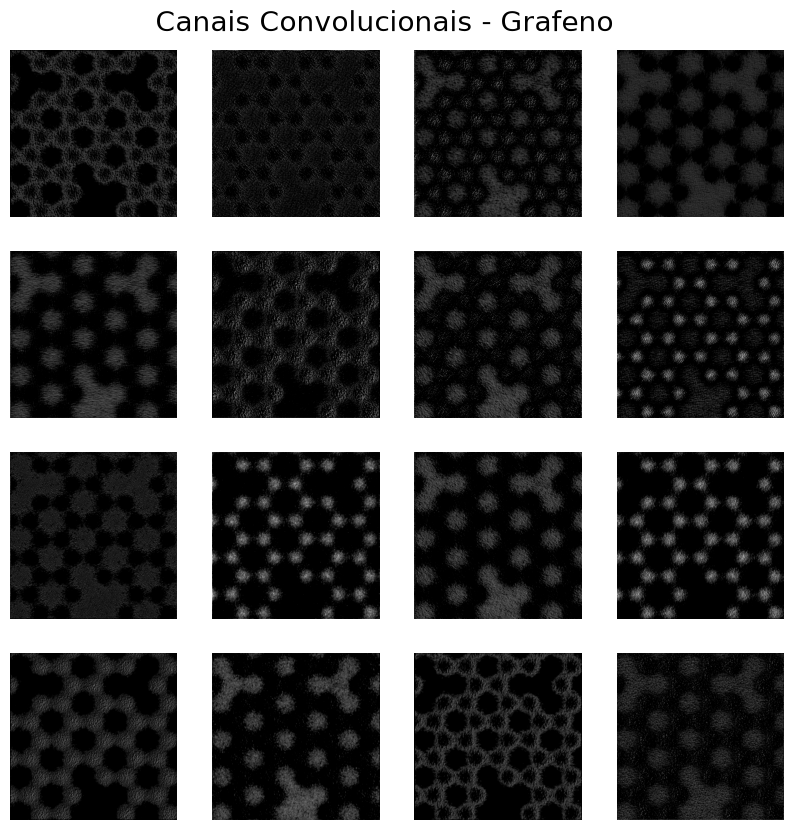

In [29]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
ax = axes.flatten()
for i in range(16):
    ax[i].axis("off")
    ax[i].imshow(convolucao.detach().numpy()[0][i,:,:], cmap='gray', vmin=0, vmax=6)

fig.suptitle("Canais Convolucionais - Grafeno", fontsize=20, y=0.92)

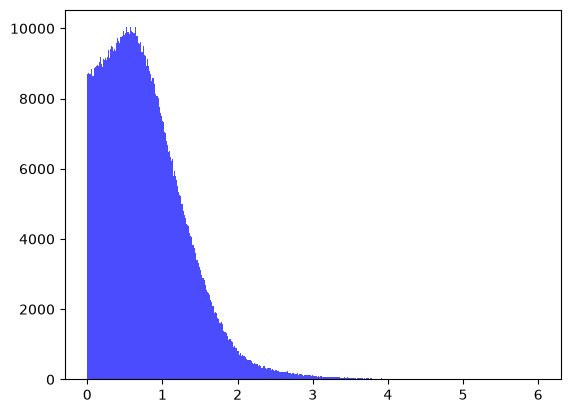

In [30]:
pixels_conv =  convolucao.detach().numpy().flatten()
pixels_conv = pixels_conv[np.round(pixels_conv,6) != 0]

plt.hist(pixels_conv, bins=1000, color='blue', alpha=0.7)
plt.show()

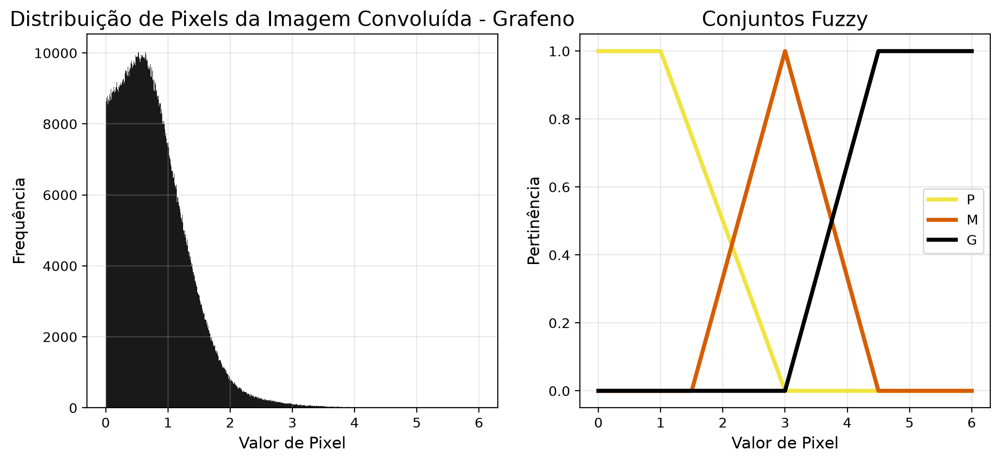

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12,5), dpi=200)

axes[0].hist(pixels_conv, bins=1000, color='black', alpha=0.9)
axes[0].set_title("Distribuição de Pixels da Imagem Convoluída - Grafeno", fontsize=15)
axes[0].grid(alpha=0.3)
axes[0].set_xlabel(r"Valor de Pixel", fontsize=12)
axes[0].set_ylabel(r"Frequência", fontsize=12)


rmax = 6

x = torch.Tensor(np.linspace(0, rmax, 1001))
x_dim = x.unsqueeze(0).unsqueeze(0).unsqueeze(0)  # (1, 1, 1, 1001)

fpert = ConjsFuzzy(rmax)
conjs = fpert(x_dim)

conjs = conjs.squeeze().detach()  # (3, 1001)

axes[1].plot(x, conjs[0], lw = 3, label= "P", color="#F0E442")
axes[1].plot(x, conjs[1], lw = 3, label = "M", color="#D55E00")
axes[1].plot(x, conjs[2], lw = 3, label= "G", color="black")
axes[1].set_xlabel(r"Valor de Pixel", fontsize=12)
axes[1].set_ylabel(r"Pertinência", fontsize=12)
axes[1].set_title("Conjuntos Fuzzy", fontsize=15)
axes[1].grid(alpha=0.3)
axes[1].legend()
plt.show()


In [32]:
convolucao.shape

torch.Size([1, 16, 512, 512])

In [33]:
teste_conv_max = crisp_pool_same(convolucao, "max", kernel_size=3, stride=2)
aaaaaaa = teste_conv_max.detach().numpy()[0]

Text(0.5, 0.92, 'MaxPooling após convolução - Grafeno')

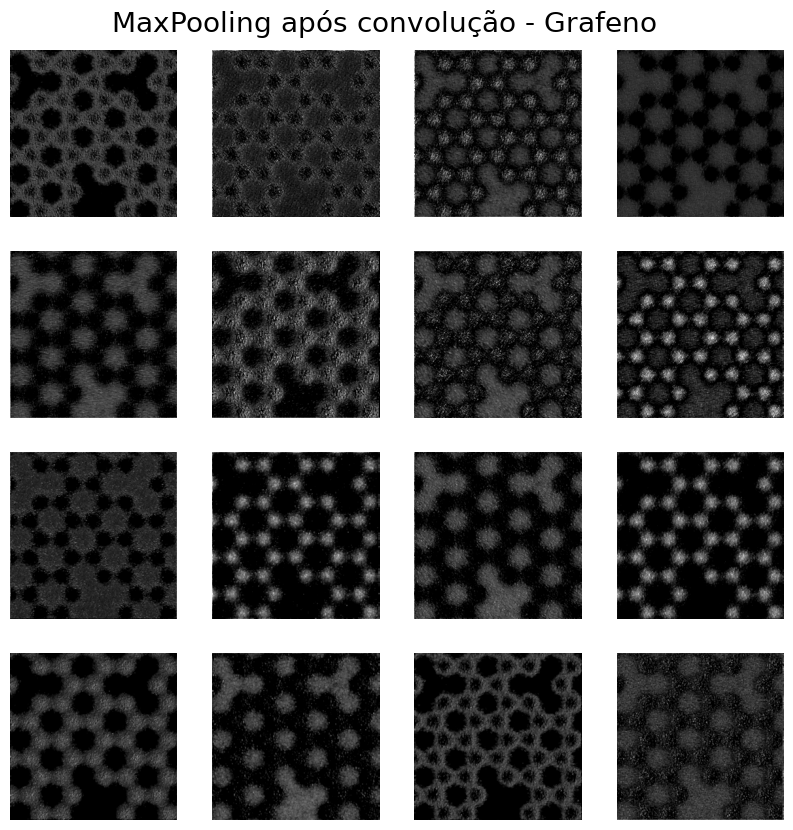

In [34]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
ax = axes.flatten()
for i in range(16):
    ax[i].axis("off")
    ax[i].imshow(aaaaaaa[i,:,:], cmap='gray', vmin=0, vmax=6)

fig.suptitle("MaxPooling após convolução - Grafeno", fontsize=20,y=0.92)

In [35]:
FP2 = FuzzyPooling(tamanho_kernel=3, stride=2)
teste_conv_FP = FP2(convolucao)

In [36]:
teste_conv_FP.shape

torch.Size([1, 16, 256, 256])

Text(0.5, 0.92, 'FuzzyPooling após convolução - Grafeno')

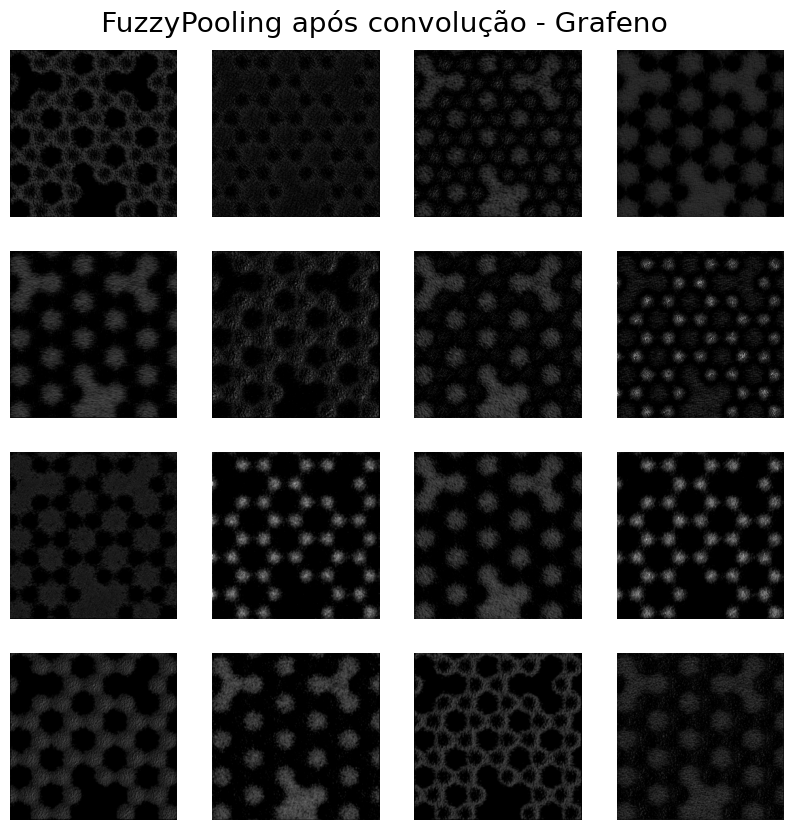

In [37]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
ax = axes.flatten()
for i in range(16):
    ax[i].axis("off")
    ax[i].imshow(teste_conv_FP.detach().numpy()[0][i,:,:], cmap='gray', vmin=0, vmax=6)

fig.suptitle("FuzzyPooling após convolução - Grafeno", fontsize=20, y=0.92)

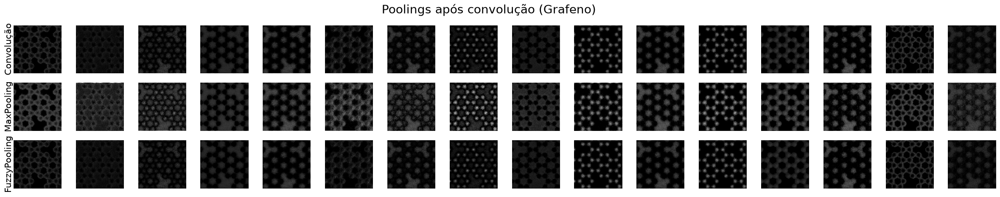

In [38]:
fig, axes = plt.subplots(3, 16, figsize=(30, 5))

fig.suptitle("Poolings após convolução (Grafeno)", fontsize=20)

# axes[0,0].supylabel("Convolução", fontsize=15)
# axes[1,0].set_ylabel("MaxPooling", fontsize=15)
# axes[2,0].set_ylabel("FuzzyPooling", fontsize=15)

labels = ["Convolução", "MaxPooling", "FuzzyPooling"]

for i, label in enumerate(labels):
    axes[i, 0].text(
        -0.1, 0.5, label,
        transform=axes[i, 0].transAxes,
        rotation=90,
        va="center",
        ha="center",
        fontsize=15
    )

for i in range(16):
    axes[0, i].axis('off')
    axes[0, i].imshow(convolucao.detach().numpy()[0][i,:,:], cmap='gray', vmin=0, vmax=6)

    axes[2, i].axis('off')
    axes[2, i].imshow(teste_conv_FP.detach().numpy()[0][i,:,:], cmap='gray', vmin=0, vmax=6)

    axes[1, i].axis('off')
    axes[1, i].imshow(aaaaaaa[i,:,:], cmap='gray', vmin=0, vmax=6)

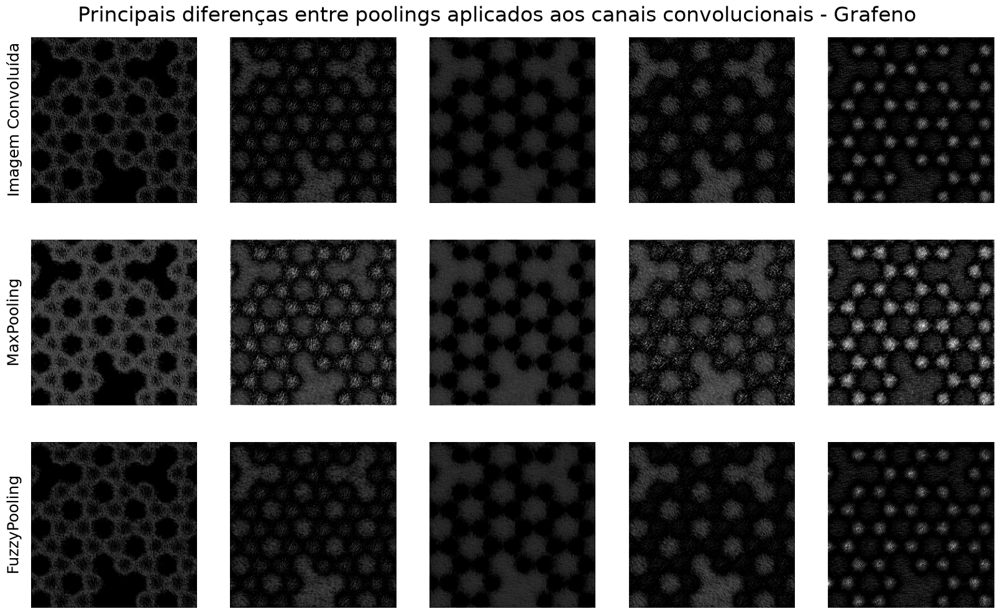

In [39]:
best = [0,2,3,6,7]

fig, axes = plt.subplots(3, len(best), figsize=(20,12))

fig.suptitle("Principais diferenças entre poolings aplicados aos canais convolucionais - Grafeno", fontsize=24, y=0.92)

# axes[0,0].supylabel("Convolução", fontsize=15)
# axes[1,0].set_ylabel("MaxPooling", fontsize=15)
# axes[2,0].set_ylabel("FuzzyPooling", fontsize=15)

labels = ["Imagem Convoluída", "MaxPooling", "FuzzyPooling"]

for i, label in enumerate(labels):
    axes[i, 0].text(
        -0.1, 0.5, label,
        transform=axes[i, 0].transAxes,
        rotation=90,
        va="center",
        ha="center",
        fontsize=18
    )

for i, im in enumerate(best):

    axes[0, i].axis('off')
    axes[0, i].imshow(convolucao.detach().numpy()[0][im,:,:], cmap='gray', vmin=0, vmax=6)

    axes[2, i].axis('off')
    axes[2, i].imshow(teste_conv_FP.detach().numpy()[0][im,:,:], cmap='gray', vmin=0, vmax=6)

    axes[1, i].axis('off')
    axes[1, i].imshow(aaaaaaa[im,:,:], cmap='gray', vmin=0, vmax=6)

Text(0.5, 0.92, 'Conjuntos fuzzy atribuídos aos canais convolucionais - Grafeno')

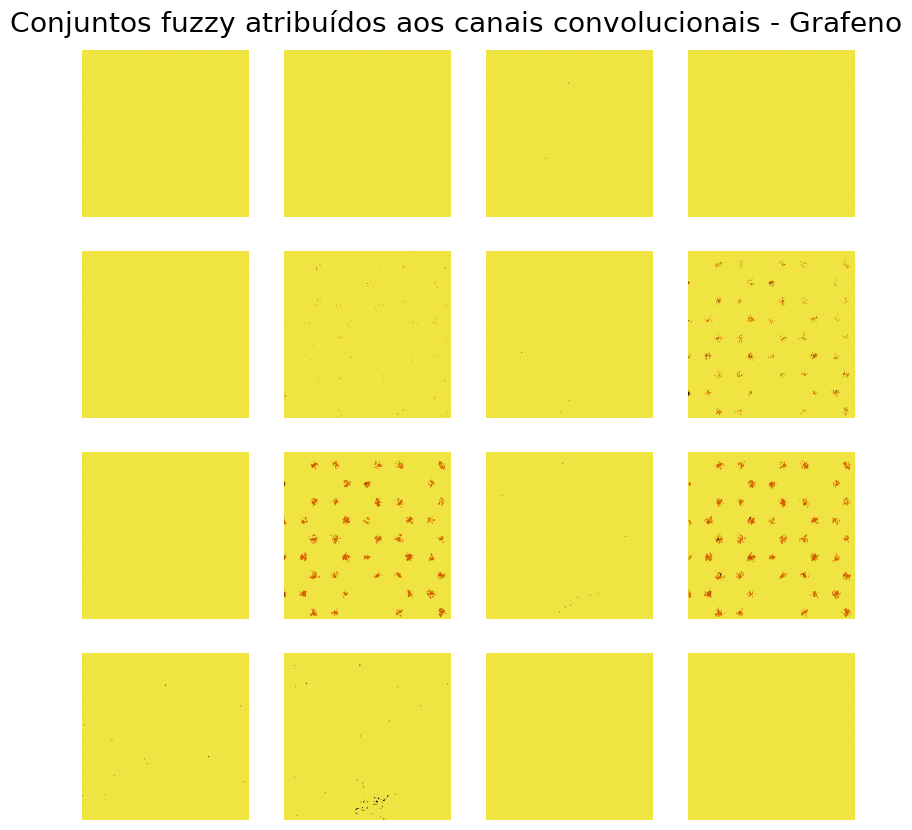

In [40]:
from matplotlib.colors import ListedColormap

cmap_3 = ListedColormap(["#F0E442", "#D55E00", "black"])

# One selected fuzzy-set index per channel and output position.
conjuntos = FP2.indices[:, :, 0, 0, :].reshape(
    FP2.indices.shape[0], FP2.indices.shape[1],
    teste_conv_FP.shape[-2], teste_conv_FP.shape[-1],
)[0]

fig, axes = plt.subplots(4, 4, figsize=(10, 10))
ax = axes.flatten()
for i in range(16):
    ax[i].axis("off")
    ax[i].imshow(conjuntos[i,:,:], cmap=cmap_3)

fig.suptitle("Conjuntos fuzzy atribuídos aos canais convolucionais - Grafeno", fontsize=20,y=0.92)

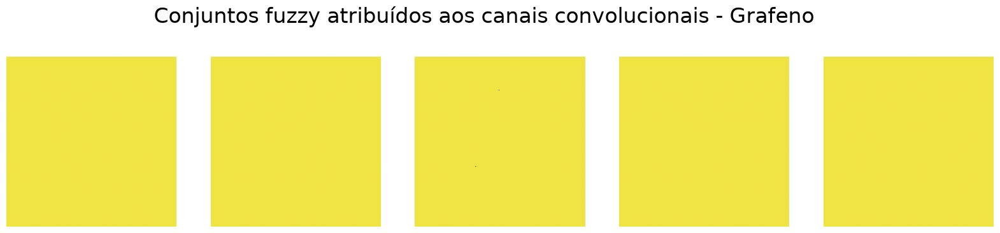

In [41]:
from matplotlib.colors import ListedColormap

cmap_3 = ListedColormap(["#F0E442", "#D55E00", "black"])

fig, axes = plt.subplots(1, len(best), figsize=(20,5))

fig.suptitle("Conjuntos fuzzy atribuídos aos canais convolucionais - Grafeno", fontsize=24, y=0.92)

# axes[0,0].supylabel("Convolução", fontsize=15)
# axes[1,0].set_ylabel("MaxPooling", fontsize=15)
# axes[2,0].set_ylabel("FuzzyPooling", fontsize=15)


for i, im in enumerate(best):

    axes[i].axis('off')
    axes[i].imshow(conjuntos[i,:,:], cmap=cmap_3)

In [42]:
aaaaaaa = restore_size(torch.tensor(aaaaaaa).unsqueeze(0), (512,512))
teste_conv_FP = restore_size(teste_conv_FP, (512,512))

conv_ch = [convolucao, aaaaaaa, teste_conv_FP]
method = ["Convolução", "MaxPooling", "FuzzyPooling"]

In [43]:
crms = np.zeros((3,16)) 

for p in range(3):
    for i in range(16):
        chs = torch.as_tensor(conv_ch[p][0][i]).float()

        crms[p,i] = torch.std(chs, correction=0)

for p in range(3):
    print(method[p], " ~ Crms Médio: ", np.mean(crms[p]))

Convolução  ~ Crms Médio:  0.5491368714720011
MaxPooling  ~ Crms Médio:  0.6918817739933729
FuzzyPooling  ~ Crms Médio:  0.4461600696668029


C:\Users\yasmin24023\AppData\Local\Temp\ipykernel_30908\2204837498.py:7: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:821.)
  crms[p,i] = torch.std(chs, correction=0)


In [44]:
psnr = np.zeros((2,16)) #método, imagem

for p in range(2):
    for i in range(16):
        ch_ref = conv_ch[0][0][i].detach().numpy()
        ch = conv_ch[p+1][0][i].detach().numpy()

        psnr[p,i] = peak_signal_noise_ratio(
            ch_ref,
            ch,
            data_range=6
        )

for p in range(2):
    print(method[p+1], " ~ PSNR Médio: ", np.mean(psnr[p]))

MaxPooling  ~ PSNR Médio:  21.436798817984336
FuzzyPooling  ~ PSNR Médio:  27.314377206350958


In [45]:
ssim = np.zeros((2,16)) #método, imagem

for p in range(2):
    for i in range(16):
        ch_ref = conv_ch[0][0][i].detach().numpy()
        ch = conv_ch[p+1][0][i].detach().numpy()


        ssim[p,i] = structural_similarity(
            ch_ref,
            ch,
            data_range=6
        )

for p in range(2):
    print(method[p+1], " ~ SSim Médio: ", np.mean(ssim[p]))

MaxPooling  ~ SSim Médio:  0.5111839810918661
FuzzyPooling  ~ SSim Médio:  0.7370021025250948


#### MoS2

In [46]:
imagem = mos2_img.astype(np.float32)
input_data = torch.from_numpy(imagem).unsqueeze(0)

In [47]:
torch.manual_seed(42)
conv = DoubleConv(1, 16)
convolucao = conv(input_data)

Text(0.5, 0.92, 'Canais Convolucionais - MoS$_2$')

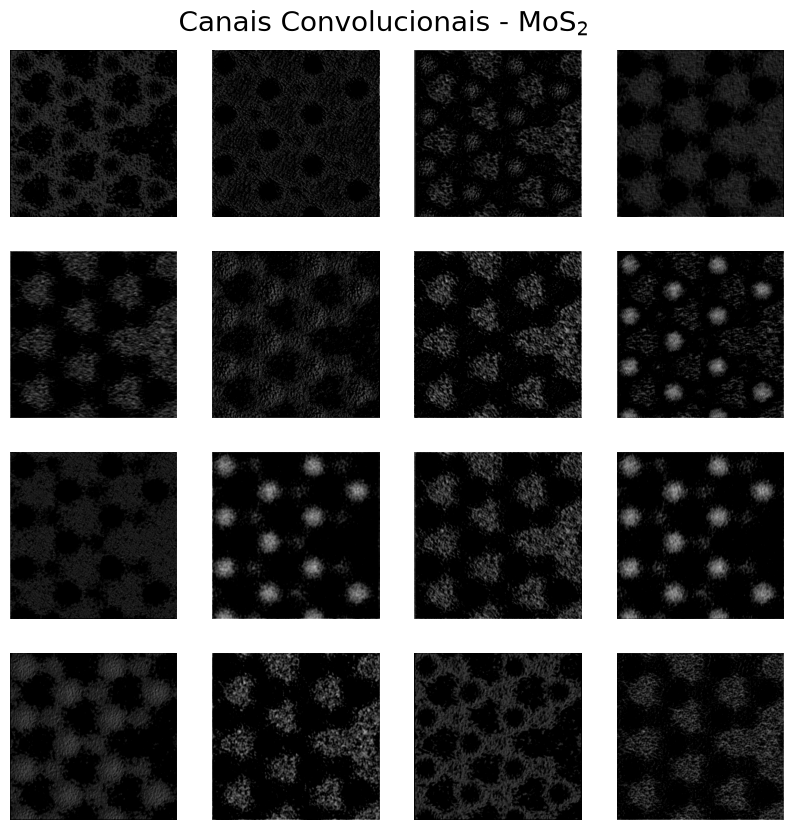

In [48]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
ax = axes.flatten()
for i in range(16):
    ax[i].axis("off")
    ax[i].imshow(convolucao.detach().numpy()[0][i,:,:], cmap='gray', vmin=0, vmax=6)

fig.suptitle("Canais Convolucionais - MoS$_2$", fontsize=20, y=0.92)

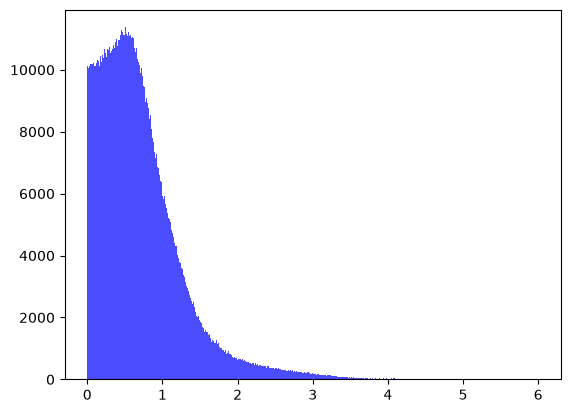

In [49]:
pixels_conv =  convolucao.detach().numpy().flatten()
pixels_conv = pixels_conv[np.round(pixels_conv,6) != 0]

plt.hist(pixels_conv, bins=1000, color='blue', alpha=0.7)
plt.show()

In [50]:
teste_conv_max = crisp_pool_same(convolucao, "max", kernel_size=3, stride=2)
aaaaaaa = teste_conv_max.detach().numpy()[0]

Text(0.5, 0.92, 'MaxPooling após convolução - MoS$_2$')

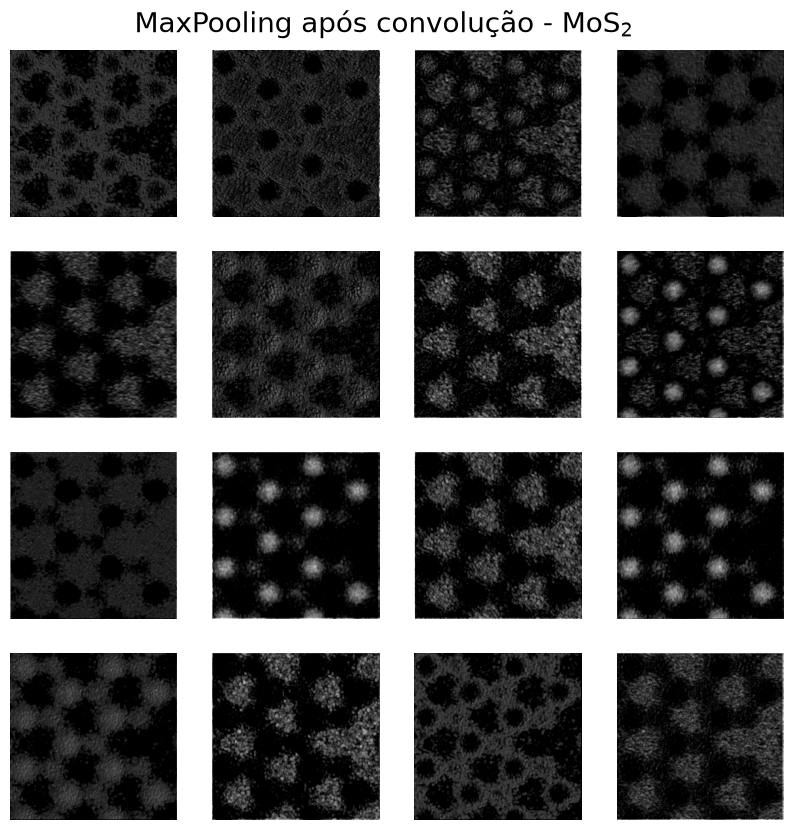

In [51]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
ax = axes.flatten()
for i in range(16):
    ax[i].axis("off")
    ax[i].imshow(aaaaaaa[i,:,:], cmap='gray', vmin=0, vmax=6)

fig.suptitle("MaxPooling após convolução - MoS$_2$", fontsize=20, y=0.92)

In [52]:
FP2 = FuzzyPooling(tamanho_kernel=3, stride=2)
teste_conv_FP = FP2(convolucao)

Text(0.5, 0.92, 'FP (Padrão) após convolução - MoS$_2$')

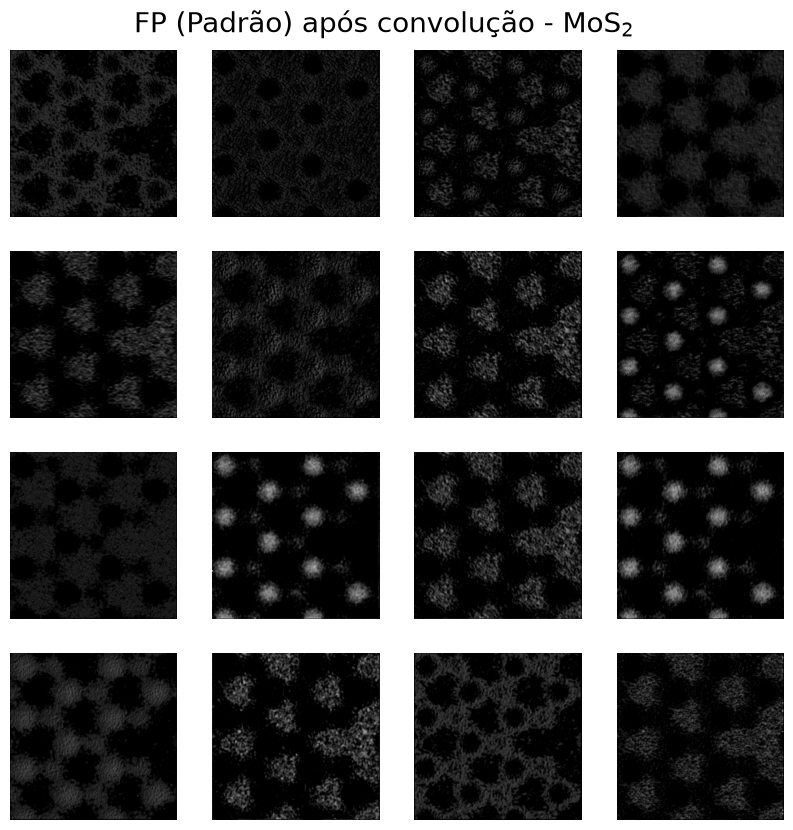

In [53]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
ax = axes.flatten()
for i in range(16):
    ax[i].axis("off")
    ax[i].imshow(teste_conv_FP.detach().numpy()[0][i,:,:], cmap='gray', vmin=0, vmax=6)

fig.suptitle("FP (Padrão) após convolução - MoS$_2$", fontsize=20, y=0.92)

Text(0.5, 0.92, 'Conjuntos fuzzy atribuídos aos canais convolucionais - MoS$_2$')

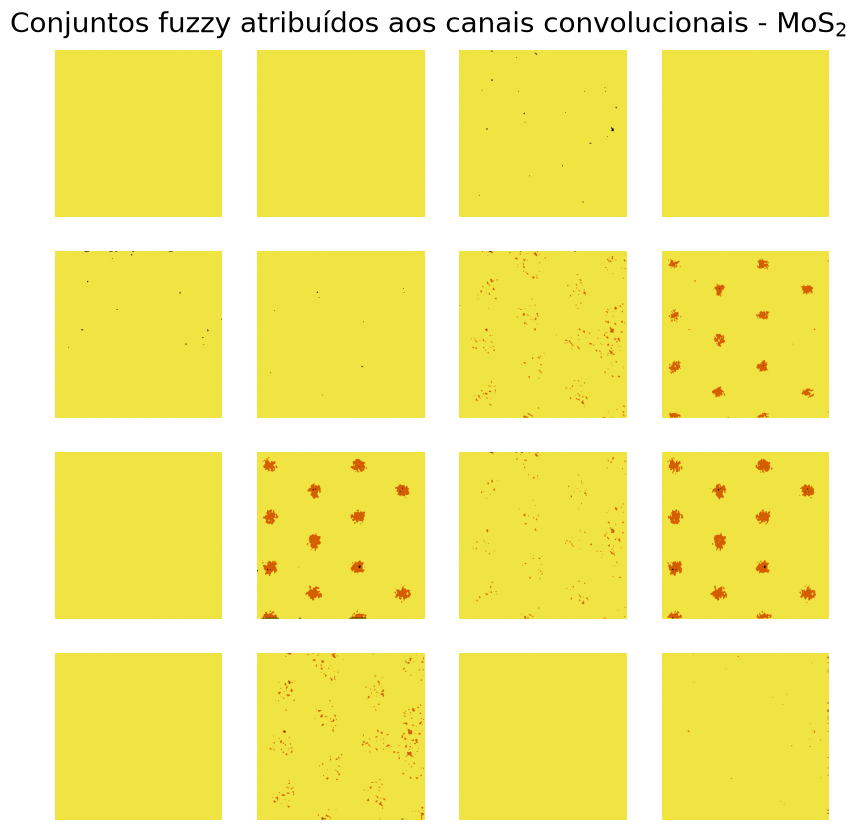

In [54]:

conjuntos = FP2.indices[:, :, 0, 0, :].reshape(
    FP2.indices.shape[0], FP2.indices.shape[1],
    teste_conv_FP.shape[-2], teste_conv_FP.shape[-1],
)[0]

fig, axes = plt.subplots(4, 4, figsize=(10, 10))
ax = axes.flatten()
for i in range(16):
    ax[i].axis("off")
    ax[i].imshow(conjuntos[i,:,:], cmap=cmap_3)

fig.suptitle("Conjuntos fuzzy atribuídos aos canais convolucionais - MoS$_2$", fontsize=20,y=0.92)

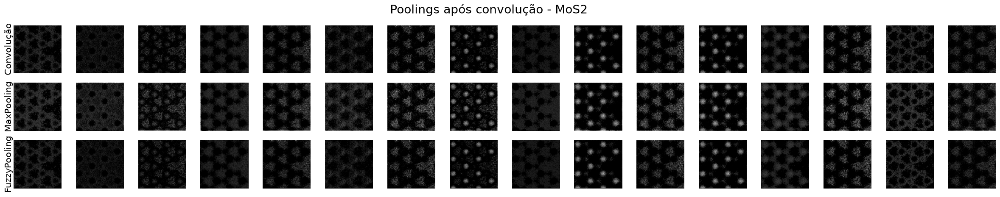

In [55]:
fig, axes = plt.subplots(3, 16, figsize=(30, 5))

fig.suptitle("Poolings após convolução - MoS2", fontsize=20)

# axes[0,0].supylabel("Convolução", fontsize=15)
# axes[1,0].set_ylabel("MaxPooling", fontsize=15)
# axes[2,0].set_ylabel("FuzzyPooling", fontsize=15)

labels = ["Convolução", "MaxPooling", "FuzzyPooling"]

for i, label in enumerate(labels):
    axes[i, 0].text(
        -0.1, 0.5, label,
        transform=axes[i, 0].transAxes,
        rotation=90,
        va="center",
        ha="center",
        fontsize=15
    )

for i in range(16):
    axes[0, i].axis('off')
    axes[0, i].imshow(convolucao.detach().numpy()[0][i,:,:], cmap='gray', vmin=0, vmax=6)

    axes[2, i].axis('off')
    axes[2, i].imshow(teste_conv_FP.detach().numpy()[0][i,:,:], cmap='gray', vmin=0, vmax=6)

    axes[1, i].axis('off')
    axes[1, i].imshow(aaaaaaa[i,:,:], cmap='gray', vmin=0, vmax=6)

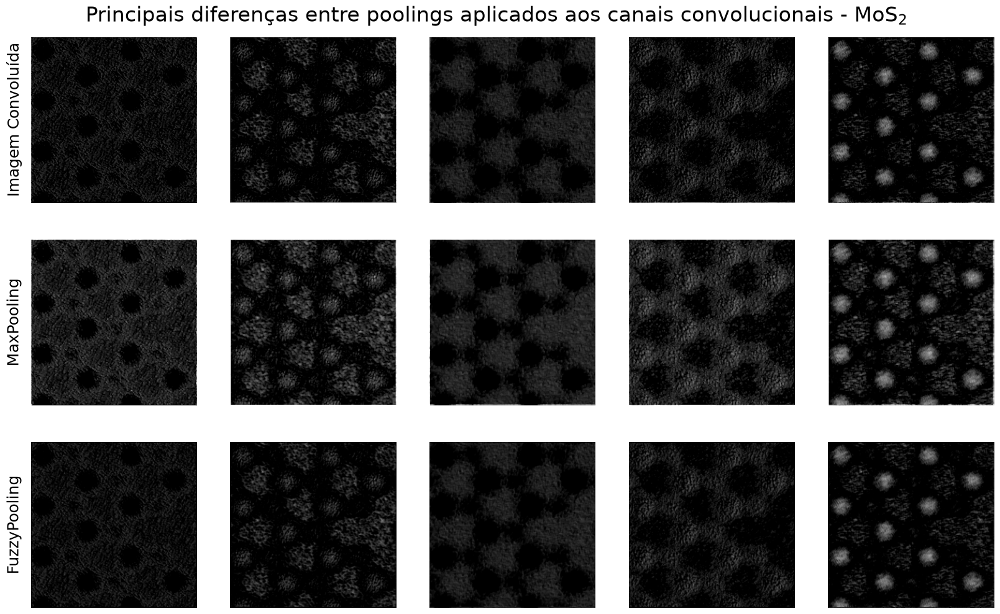

In [56]:
best = [1,2,3,5,7]

fig, axes = plt.subplots(3, len(best), figsize=(20,12))

fig.suptitle("Principais diferenças entre poolings aplicados aos canais convolucionais - MoS$_2$", fontsize=24, y=0.92)

# axes[0,0].supylabel("Convolução", fontsize=15)
# axes[1,0].set_ylabel("MaxPooling", fontsize=15)
# axes[2,0].set_ylabel("FuzzyPooling", fontsize=15)

labels = ["Imagem Convoluída", "MaxPooling", "FuzzyPooling"]

for i, label in enumerate(labels):
    axes[i, 0].text(
        -0.1, 0.5, label,
        transform=axes[i, 0].transAxes,
        rotation=90,
        va="center",
        ha="center",
        fontsize=18
    )

for i, im in enumerate(best):

    axes[0, i].axis('off')
    axes[0, i].imshow(convolucao.detach().numpy()[0][im,:,:], cmap='gray', vmin=0, vmax=6)

    axes[2, i].axis('off')
    axes[2, i].imshow(teste_conv_FP.detach().numpy()[0][im,:,:], cmap='gray', vmin=0, vmax=6)

    axes[1, i].axis('off')
    axes[1, i].imshow(aaaaaaa[im,:,:], cmap='gray', vmin=0, vmax=6)

##### MoS2 ~ Fuzzy Pooling com 6 conjuntos

In [57]:
def EP(x):

    pert_EP = torch.where( # Se
        x < 1, # x é baixo, região de pertinência máxima do conjunto P,
        (1-x), # preenche com pertinência 1;
        torch.zeros_like(x) # Caso contrário, preenche com pertinência 0.
        )
    
    return pert_EP


def MP(x):

    pert_MP = torch.where( # Se
        (x >= 0) & (x <= 1), # x é médio-baixo, pertinência linear crescente para M,
        (x), # calcula a pertinência;
        torch.where( # Se não, 
            (x > 1) & (x < 2), # x é médio-alto, pertinência linear decrescente para M,
            (2 - x), # calcula a pertinência;
            torch.zeros_like(x) # Caso contrário, preenche com pertinência 0.
        )
    )
    
    return pert_MP


def P(x):

    pert_P = torch.where( # Se
        (x >= 1) & (x <= 2), # x é médio-baixo, pertinência linear crescente para M,
        (x - 1), # calcula a pertinência;
        torch.where( # Se não, 
            (x > 2) & (x < 3), # x é médio-alto, pertinência linear decrescente para M,
            (3 - x), # calcula a pertinência;
            torch.zeros_like(x) # Caso contrário, preenche com pertinência 0.
        )
    )

    return pert_P


def M(x):

    pert_M = torch.where( # Se
        (x >= 2) & (x <= 3), # x é médio-baixo, pertinência linear crescente para M,
        (x - 2), # calcula a pertinência;
        torch.where( # Se não, 
            (x > 3) & (x < 4), # x é médio-alto, pertinência linear decrescente para M,
            (4 - x), # calcula a pertinência;
            torch.zeros_like(x) # Caso contrário, preenche com pertinência 0.
        )
    )

    return pert_M


def G(x):

    pert_G = torch.where( # Se
        (x >= 3) & (x <= 4), # x é médio-baixo, pertinência linear crescente para M,
        (x - 3), # calcula a pertinência;
        torch.where( # Se não, 
            (x > 4) & (x < 5), # x é médio-alto, pertinência linear decrescente para M,
            (5 - x), # calcula a pertinência;
            torch.zeros_like(x) # Caso contrário, preenche com pertinência 0.
        )
    )

    return pert_G


def MG(x):

    pert_MG = torch.where( # Se
        x < 4, # x é pequeno, região de pertinência mínima do conjunto G,
        torch.zeros_like(x), # preenche com pertinência 0;
        torch.where( # Se não,
            x <= 5, # x é médio-alto, pertinência linear crescente para G,
            (x - 4), # calcula a pertinência;
            torch.ones_like(x) # Caso contrário, preecnhe com pertinência 1.
        )
    )

    return pert_MG



def PPPMGG(x):

    # Concatena as pertiências de cada conjunto fuzzy em um único tensor
    pertinencias = torch.stack(
        [
            EP(x),
            MP(x),
            P(x),
            M(x),
            G(x),
            MG(x)
        ],
        dim=2 # Aloca as pertinências por canal
    )

    return pertinencias

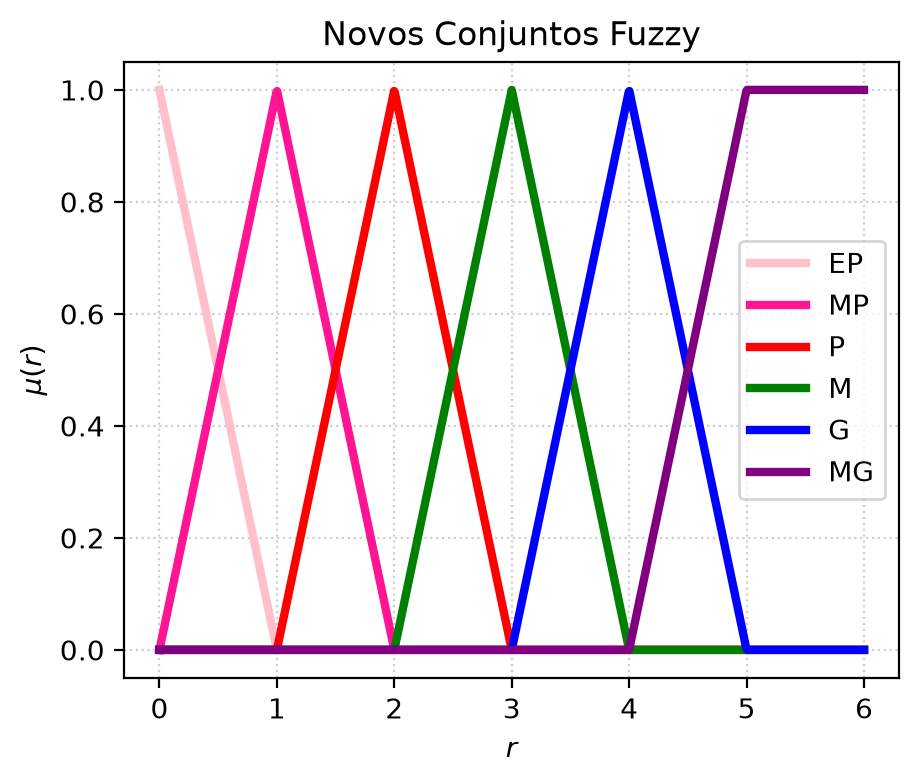

In [58]:
rmax = 6

x = torch.Tensor(np.linspace(0, rmax, 1001))
x_dim = x.unsqueeze(0).unsqueeze(0).unsqueeze(0)  # (1, 1, 1, 1001)

conjs = PPPMGG(x_dim)

conjs = conjs.squeeze().detach()  # (3, 1001)

plt.figure(figsize=(5,4), dpi=200)
plt.plot(x, conjs[0], lw = 3, label= "EP", color= "pink")
plt.plot(x, conjs[1], lw = 3, label= "MP", color= "deeppink")
plt.plot(x, conjs[2], lw = 3, label = "P", color= "red")
plt.plot(x, conjs[3], lw = 3, label= "M", color="green")
plt.plot(x, conjs[4], lw = 3, label = "G", color= "blue")
plt.plot(x, conjs[5], lw = 3, label= "MG", color="purple")
plt.xlabel(r"$r$")
plt.ylabel(r"$\mu(r)$")
plt.title("Novos Conjuntos Fuzzy")
plt.grid(alpha=0.6, linestyle=":")
plt.legend()
plt.show()

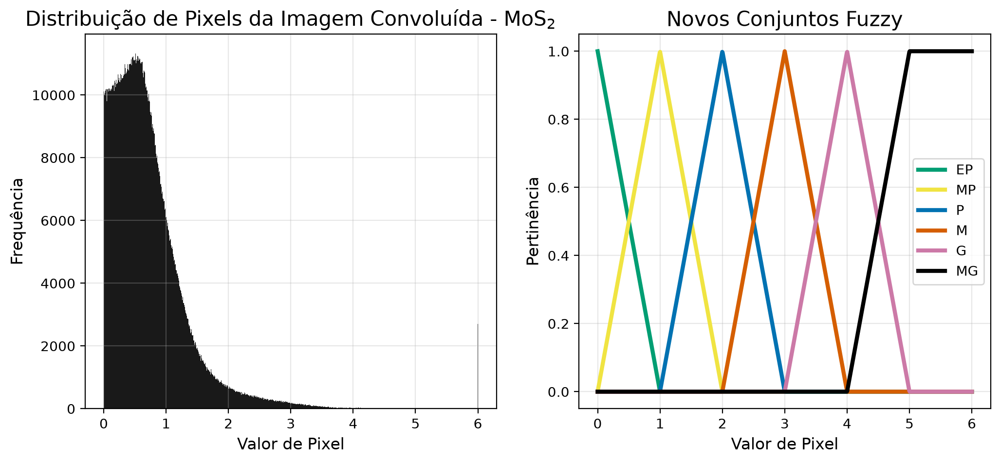

In [59]:
cmap_okabeito = ["#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7", "black"]

fig, axes = plt.subplots(1, 2, figsize=(12,5), dpi=200)

axes[0].hist(pixels_conv, bins=1000, color='black', alpha=0.9)
axes[0].set_title("Distribuição de Pixels da Imagem Convoluída - MoS$_2$", fontsize=15)
axes[0].grid(alpha=0.3)
axes[0].set_xlabel(r"Valor de Pixel", fontsize=12)
axes[0].set_ylabel(r"Frequência", fontsize=12)



rmax = 6

x = torch.Tensor(np.linspace(0, rmax, 1001))
x_dim = x.unsqueeze(0).unsqueeze(0).unsqueeze(0)  # (1, 1, 1, 1001)

# fpert = ConjsFuzzy(rmax)
# conjs = fpert(x_dim)
# conjs = conjs.squeeze().detach()  # (3, 1001)

# axes[1].plot(x, conjs[0], lw = 3, label= "P", color= cmap_okabeito[1])
# axes[1].plot(x, conjs[1], lw = 3, label = "M", color=cmap_okabeito[3])
# axes[1].plot(x, conjs[2], lw = 3, label= "G", color=cmap_okabeito[5])
# axes[1].set_xlabel(r"Valor de Pixel", fontsize=15)
# axes[1].set_ylabel(r"Pertinência", fontsize=15)
# axes[1].set_title("Conjuntos Fuzzy Padrão", fontsize=18)
# axes[1].tick_params(axis="x", labelsize=12)
# axes[1].tick_params(axis="y", labelsize=12)
# axes[1].grid(alpha=0.3)
# axes[1].legend(fontsize=12)

conjs = PPPMGG(x_dim)
conjs = conjs.squeeze().detach()  # (3, 1001)

axes[1].plot(x, conjs[0], lw = 3, label= "EP", color= cmap_okabeito[0])
axes[1].plot(x, conjs[1], lw = 3, label= "MP", color= cmap_okabeito[1])
axes[1].plot(x, conjs[2], lw = 3, label = "P", color= cmap_okabeito[2])
axes[1].plot(x, conjs[3], lw = 3, label= "M", color=cmap_okabeito[3])
axes[1].plot(x, conjs[4], lw = 3, label = "G", color= cmap_okabeito[4])
axes[1].plot(x, conjs[5], lw = 3, label= "MG", color=cmap_okabeito[5])
axes[1].set_xlabel(r"Valor de Pixel", fontsize=12)
axes[1].set_ylabel(r"Pertinência", fontsize=12)
axes[1].set_title("Novos Conjuntos Fuzzy", fontsize=15)
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.show()

In [60]:
FP2_new = FuzzyPooling(tamanho_kernel=3, stride=2, funcs_pertinencia=PPPMGG)
teste_conv_FP_new = FP2_new(convolucao)

Text(0.5, 0.92, 'FP (Novos Conjuntos) após convolução - MoS$_2$')

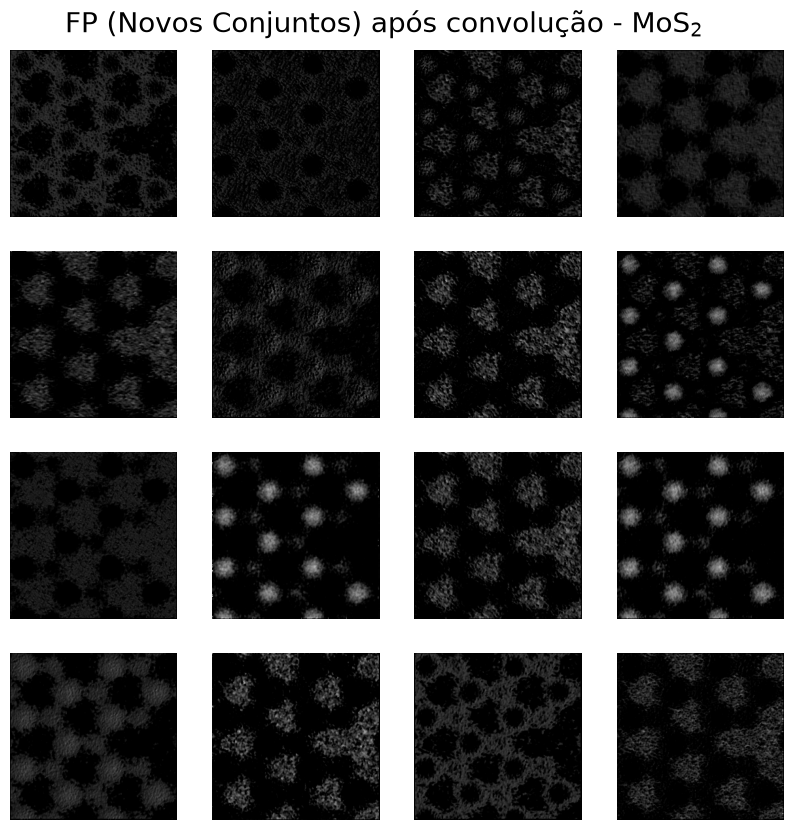

In [61]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
ax = axes.flatten()
for i in range(16):
    ax[i].axis("off")
    ax[i].imshow(teste_conv_FP_new.detach().numpy()[0][i,:,:], cmap='gray', vmin=0, vmax=6)

fig.suptitle("FP (Novos Conjuntos) após convolução - MoS$_2$", fontsize=20, y=0.92)

Text(0.5, 0.92, 'Novos conjuntos fuzzy atribuídos aos canais convolucionais - MoS$_2$')

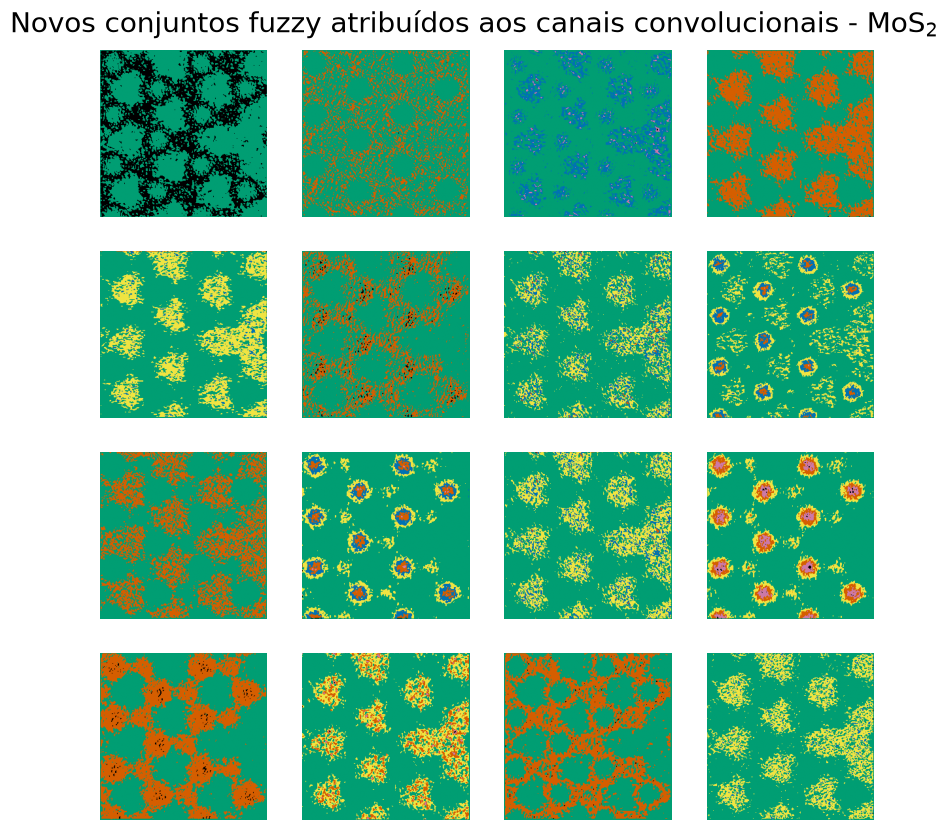

In [62]:
cmap_3 = ListedColormap(["#F0E442", "#D55E00", "black"])
cmap_6 = ListedColormap(cmap_okabeito)

conjuntos_new = FP2_new.indices[:, :, 0, 0, :].reshape(
    FP2_new.indices.shape[0], FP2_new.indices.shape[1],
    teste_conv_FP_new.shape[-2], teste_conv_FP_new.shape[-1],
)[0]

fig, axes = plt.subplots(4, 4, figsize=(10, 10))
ax = axes.flatten()
for i in range(16):
    ax[i].axis("off")
    ax[i].imshow(conjuntos_new[i,:,:], cmap=cmap_6)

fig.suptitle("Novos conjuntos fuzzy atribuídos aos canais convolucionais - MoS$_2$", fontsize=20,y=0.92)

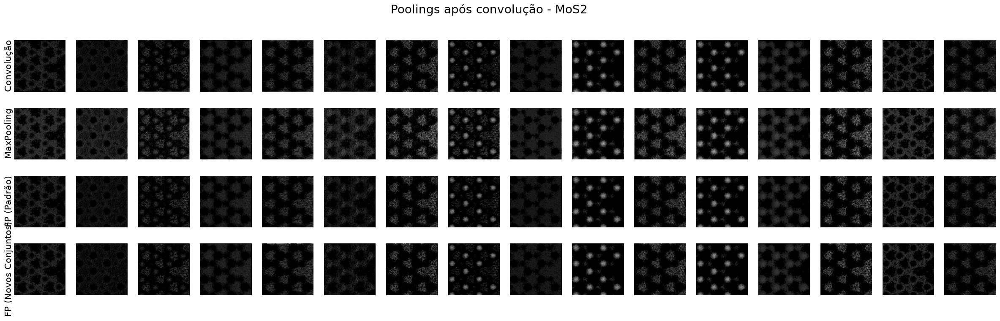

In [63]:
fig, axes = plt.subplots(4, 16, figsize=(30, 8))

fig.suptitle("Poolings após convolução - MoS2", fontsize=20)

# axes[0,0].supylabel("Convolução", fontsize=15)
# axes[1,0].set_ylabel("MaxPooling", fontsize=15)
# axes[2,0].set_ylabel("FuzzyPooling", fontsize=15)

labels = ["Convolução", "MaxPooling", "FP (Padrão)", "FP (Novos Conjuntos)"]

for i, label in enumerate(labels):
    axes[i, 0].text(
        -0.1, 0.5, label,
        transform=axes[i, 0].transAxes,
        rotation=90,
        va="center",
        ha="center",
        fontsize=15
    )

for i in range(16):
    axes[0, i].axis('off')
    axes[0, i].imshow(convolucao.detach().numpy()[0][i,:,:], cmap='gray', vmin=0, vmax=6)

    axes[2, i].axis('off')
    axes[2, i].imshow(teste_conv_FP.detach().numpy()[0][i,:,:], cmap='gray', vmin=0, vmax=6)

    axes[3, i].axis('off')
    axes[3, i].imshow(teste_conv_FP_new.detach().numpy()[0][i,:,:], cmap='gray', vmin=0, vmax=6)

    axes[1, i].axis('off')
    axes[1, i].imshow(aaaaaaa[i,:,:], cmap='gray', vmin=0, vmax=6)

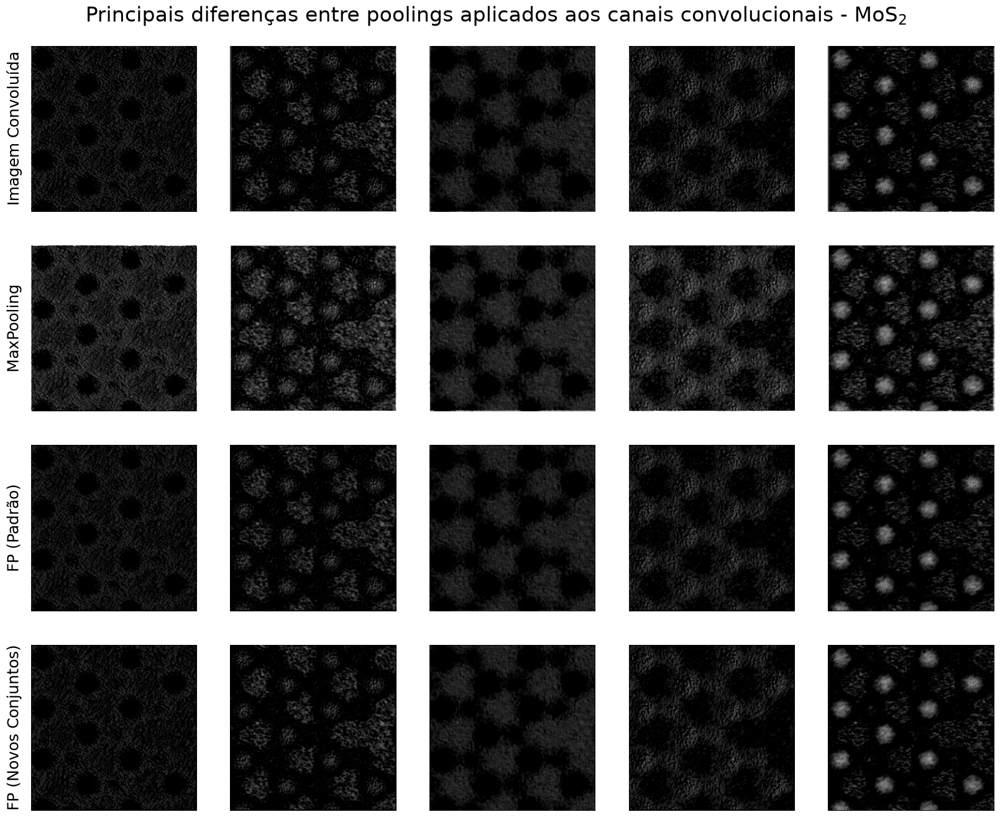

In [64]:
best = [1,2,3,5,7]

fig, axes = plt.subplots(4, len(best), figsize=(20,16))

fig.suptitle("Principais diferenças entre poolings aplicados aos canais convolucionais - MoS$_2$", fontsize=24, y=0.92)

# axes[0,0].supylabel("Convolução", fontsize=15)
# axes[1,0].set_ylabel("MaxPooling", fontsize=15)
# axes[2,0].set_ylabel("FuzzyPooling", fontsize=15)

labels = ["Imagem Convoluída", "MaxPooling", "FP (Padrão)", "FP (Novos Conjuntos)"]

for i, label in enumerate(labels):
    axes[i, 0].text(
        -0.1, 0.5, label,
        transform=axes[i, 0].transAxes,
        rotation=90,
        va="center",
        ha="center",
        fontsize=18
    )

for i, im in enumerate(best):

    axes[0, i].axis('off')
    axes[0, i].imshow(convolucao.detach().numpy()[0][im,:,:], cmap='gray', vmin=0, vmax=6)

    axes[2, i].axis('off')
    axes[2, i].imshow(teste_conv_FP.detach().numpy()[0][im,:,:], cmap='gray', vmin=0, vmax=6)

    axes[3, i].axis('off')
    axes[3, i].imshow(teste_conv_FP_new.detach().numpy()[0][im,:,:], cmap='gray', vmin=0, vmax=6)

    axes[1, i].axis('off')
    axes[1, i].imshow(aaaaaaa[im,:,:], cmap='gray', vmin=0, vmax=6)

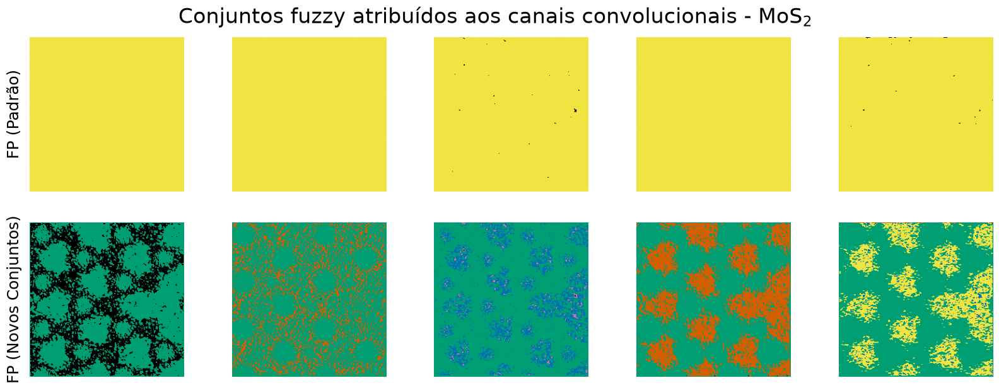

In [65]:
from matplotlib.colors import ListedColormap

cmap_3 = ListedColormap(["#F0E442", "#D55E00", "black"])
cmap_6 = ListedColormap(cmap_okabeito)

fig, axes = plt.subplots(2, len(best), figsize=(20,7))

fig.suptitle("Conjuntos fuzzy atribuídos aos canais convolucionais - MoS$_2$", fontsize=24, y=0.95)

# axes[0,0].supylabel("Convolução", fontsize=15)
# axes[1,0].set_ylabel("MaxPooling", fontsize=15)
# axes[2,0].set_ylabel("FuzzyPooling", fontsize=15)

labels = ["FP (Padrão)", "FP (Novos Conjuntos)"]

for i, label in enumerate(labels):
    axes[i, 0].text(
        -0.1, 0.5, label,
        transform=axes[i, 0].transAxes,
        rotation=90,
        va="center",
        ha="center",
        fontsize=18
    )

for i, im in enumerate(best):

    axes[0,i].axis('off')
    axes[0,i].imshow(conjuntos[i,:,:], cmap=cmap_3)
    axes[1,i].axis('off')
    axes[1,i].imshow(conjuntos_new[i,:,:], cmap=cmap_6)

In [66]:
aaaaaaa = restore_size(torch.tensor(aaaaaaa).unsqueeze(0), (512,512))
teste_conv_FP = restore_size(teste_conv_FP, (512,512))
teste_conv_FP_new = restore_size(teste_conv_FP_new, (512,512))

conv_ch = [convolucao, aaaaaaa, teste_conv_FP, teste_conv_FP_new]
method = ["Convolução", "MaxPooling", "FP (Pardrão)", "FP (Novos Conjuntos)"]

In [67]:
crms = np.zeros((4,16)) 

for p in range(4):
    for i in range(16):
        chs = torch.as_tensor(conv_ch[p][0][i]).float()

        crms[p,i] = torch.std(chs, correction=0)

for p in range(4):
    print(method[p], " ~ Crms Médio: ", np.mean(crms[p]))

Convolução  ~ Crms Médio:  0.5598480571061373
MaxPooling  ~ Crms Médio:  0.6906299199908972
FP (Pardrão)  ~ Crms Médio:  0.4643945638090372
FP (Novos Conjuntos)  ~ Crms Médio:  0.47911794669926167


In [68]:
psnr = np.zeros((3,16)) #método, imagem

for p in range(3):
    for i in range(16):
        ch_ref = conv_ch[0][0][i].detach().numpy()
        ch = conv_ch[p+1][0][i].detach().numpy()

        psnr[p,i] = peak_signal_noise_ratio(
            ch_ref,
            ch,
            data_range=6
        )

for p in range(3):
    print(method[p+1], " ~ PSNR Médio: ", np.mean(psnr[p]))

MaxPooling  ~ PSNR Médio:  23.509544965240213
FP (Pardrão)  ~ PSNR Médio:  26.92458018783794
FP (Novos Conjuntos)  ~ PSNR Médio:  26.335564392429788


In [69]:
ssim = np.zeros((3,16)) #método, imagem

for p in range(3):
    for i in range(16):
        ch_ref = conv_ch[0][0][i].detach().numpy()
        ch = conv_ch[p+1][0][i].detach().numpy()


        ssim[p,i] = structural_similarity(
            ch_ref,
            ch,
            data_range=6
        )

for p in range(3):
    print(method[p+1], " ~ SSim Médio: ", np.mean(ssim[p]))

MaxPooling  ~ SSim Médio:  0.6963606020193399
FP (Pardrão)  ~ SSim Médio:  0.8734124596454595
FP (Novos Conjuntos)  ~ SSim Médio:  0.8589064306745535
